Test, dass alles funktioniert

In [8]:
import sys

sys.path.insert(
    0,
    "/Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/src"
)

import probly

In [9]:
import sys
import sklearn
import torch

print("Python:", sys.executable)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("Alles funktioniert!")

Python: /Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/.venv/bin/python
Scikit-learn: 1.8.0
PyTorch: 2.10.0
Alles funktioniert!


1. Hier einen synthetischen Datensatz erzeugen mit 100 Datenpunkten. Das ML Modell soll lernen die Datenpunkte zu clustern. X sind die Eingabedaten mit 2 Features und y sind die Labels, die vergeben werden können. Also z.B. [0, 0, 1]

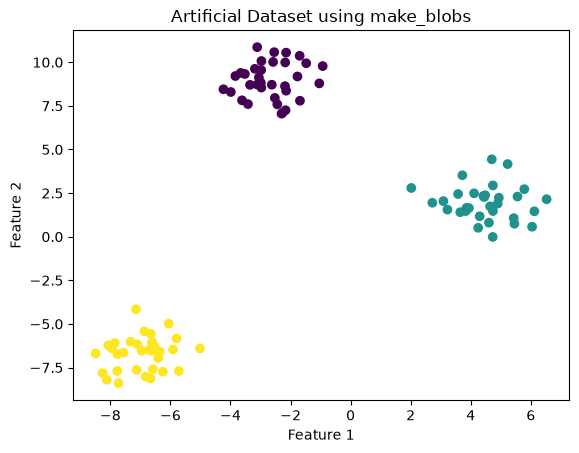

In [10]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

# Daten erzeugen
X, y = make_blobs(
    n_samples=100, #100 Datenpunkte erzeugt
    centers=3, #3 Kategorien
    n_features=2, #jeder Punkt hat 2 Eigenschaften
    random_state=42 #reproduzierbare Ergebnisse
)

# Daten visualisieren
plt.scatter(X[:, 0], X[:, 1], c=y) #bei X [[1, 2], [6, 7], [3, 4]] bedeutet X[:, 0] z.B., dass man alle Datenpunkte nimmt, aber nur das erste Feature

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Artificial Dataset using make_blobs")

plt.show()

Wir erstellen jetzt das ML Modell mit sklearn. Zuerst wird das Modell erstellt und da es hier numerische Werte sind, wird ein Regressionsmodell verwendet. Vereinfacht passiert Folgendes beim Training:
1. Das Modell untersucht die Eingabedaten.
2. Es sucht nach mathematischen Zusammenhängen zwischen Features und Labels.
3. Es berechnet passende Modellparameter (Gewichte und Bias).
4. Es passt diese Parameter so an, dass die Klassenzuordnung möglichst gut funktioniert.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Modell trainieren
model = LogisticRegression() #Regression verwendet. Hier wird nur das Modell erstellt, aber noch nicht trainiert!

model.fit(X, y) #Hier wird es schon trainiert. Und zwar mit den X_train = Eingabedaten und y_train Ausgabedaten

# Vorhersage
predictions = model.predict(X)

print("Accuracy:", accuracy_score(y, predictions))

Accuracy: 1.0


Jetzt anzeigen lassen, welche Datenpunkte welchen Klassen zugeordnet wurden. Hier gehe ich davon aus, dass negative Feature 1 und positive Feature 2 Cluster 0 zugeordnet werden. Positive Feature 1 und Feature 2 werden Cluster 1 zugeordnet. Negative Feature 1 und Feature 2 werden Cluster 2 zugeordnet.

In [12]:
import pandas as pd

df = pd.DataFrame(X, columns=["Feature 1", "Feature 2"])

df["Cluster"] = y

print(df)

    Feature 1  Feature 2  Cluster
0   -7.726421  -8.394957        2
1    5.453396   0.742305        1
2   -2.978672   9.556846        0
3    6.042673   0.571319        1
4   -6.521840  -6.319325        2
..        ...        ...      ...
95  -3.186120   9.625962        0
96  -1.478198   9.945566        0
97   4.478593   2.377221        1
98  -5.796576  -5.826308        2
99  -3.348415   8.705074        0

[100 rows x 3 columns]


2. Jetzt machen wir dasselbe, bloß in Pytorch

In [13]:
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Daten erzeugen
X, y = make_blobs(
    n_samples=500,
    centers=3,
    n_features=2,
    random_state=42
)

# Trainings- und Testdaten aufteilen
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

NumPy Daten konvertieren

In [14]:
import torch

# Features
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

# Labels
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

Neuronales Netzwerk erstellen. Jeder Datenpunkt bekommt 2 Features mit nn.Linear(2, 16) gibt es 2 Features und 16 Neuronen. nn.ReLU() ist die Aktivierungsfunktion, sie setzt negative Werte auf 0 und lässt positive Werte unverändert. nn.Linear(16, 3) definiert 3 Ausgabewerte.

In [15]:
import torch.nn as nn

# Neuronales Netzwerk erstellen
model = nn.Sequential( #hier wird das Netzwerk erstellt. statt regression in sklearn ist es hier sequential

    # Input Layer -> Hidden Layer
    nn.Linear(2, 16),

    # Aktivierungsfunktion
    nn.ReLU(),

    # Hidden Layer -> Output Layer
    nn.Linear(16, 3)
)

print(model)

Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=3, bias=True)
)


Wie lernt das Netzwerk? Hier gibt es zwei wichtige Bestandteile:

A) Loss Function

CrossEntropyLoss() misst, wie stark die Vorhersagen des Netzwerks von den tatsächlichen Klassen abweichen.

Je kleiner der Loss, desto besser sind die Vorhersagen im Allgemeinen.

B) Optimizer

Adam verändert die Gewichte des neuronalen Netzwerks, um den Loss zu reduzieren.

lr=0.01 steht für Learning Rate. Sie bestimmt, wie groß die einzelnen Anpassungsschritte sind.

In [16]:
# Loss-Funktion
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

Jetzt das Modell trainieren. 
1	zero_grad()	Alte Gradienten löschen
2	model(X_train)	Vorhersagen berechnen
3	criterion(...)	Fehler berechnen
4	loss.backward()	Gradienten berechnen
5	optimizer.step()	Gewichte aktualisieren

Diese fünf Schritte werden 100-mal wiederholt.

Das nennt man Training über 100 Epochen.

Wichtig: Eine Epoche bedeutet hier, dass das gesamte Trainingsset einmal durch das Netzwerk verarbeitet wird.

In [17]:
# Training
epochs = 100

for epoch in range(epochs):

    # 1. Alte Gradienten zurücksetzen
    optimizer.zero_grad()

    # 2. Vorhersage erstellen
    outputs = model(X_train)

    # 3. Loss berechnen
    loss = criterion(outputs, y_train)

    # 4. Backpropagation
    loss.backward()

    # 5. Gewichte aktualisieren
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {loss.item():.4f}"
        )

Epoch [10/100], Loss: 0.0858
Epoch [20/100], Loss: 0.0149
Epoch [30/100], Loss: 0.0056
Epoch [40/100], Loss: 0.0032
Epoch [50/100], Loss: 0.0023
Epoch [60/100], Loss: 0.0018
Epoch [70/100], Loss: 0.0016
Epoch [80/100], Loss: 0.0014
Epoch [90/100], Loss: 0.0012
Epoch [100/100], Loss: 0.0011


Das Modell testen. Wir verwenden dafür unsere 100 Testdatenpunkte, die das Modell während des Trainings nicht gesehen hat.
model.eval() schaltet das Netzwerk in den Evaluierungsmodus.
1. torch.no_grad() deaktiviert die Gradientenberechnung, da wir nicht mehr trainieren.
2. model(X_test) berechnet die Vorhersagen.
3. torch.argmax(outputs, dim=1) wählt für jeden Datenpunkt die Klasse mit dem höchsten Ausgabewert.
4. Wir vergleichen die Vorhersagen mit den tatsächlichen Labels.

In [18]:
# Modell in Evaluierungsmodus setzen
model.eval()

# Keine Gradienten beim Testen berechnen
with torch.no_grad():

    # Vorhersagen erstellen
    outputs = model(X_test)

    # Höchsten Score als vorhergesagte Klasse auswählen
    predictions = torch.argmax(outputs, dim=1)

    # Accuracy berechnen
    accuracy = (predictions == y_test).float().mean()

print("PyTorch Accuracy:", accuracy.item())

PyTorch Accuracy: 1.0


Datenpunkte visualisieren. und wie wurde klassifieziert?

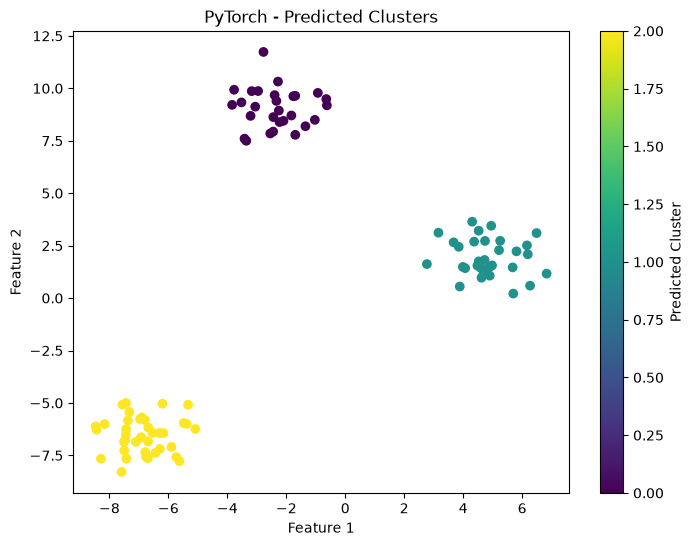

In [19]:
import matplotlib.pyplot as plt

# Tensoren zurück in NumPy umwandeln
X_test_np = X_test.numpy()
predictions_np = predictions.numpy()

plt.figure(figsize=(8, 6))

plt.scatter(
    X_test_np[:, 0],
    X_test_np[:, 1],
    c=predictions_np,
    cmap="viridis"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("PyTorch - Predicted Clusters")

plt.colorbar(label="Predicted Cluster")
plt.show()

3. Einen MC Dropout erstellen. 

In [20]:
from __future__ import annotations

from sklearn.datasets import make_moons
import torch
from torch import nn

from probly.representer import representer
from probly.transformation import dropout

from examples.utils.model import MLPClassifier
from examples.utils.plotting import plot_example_uncertainty

In [21]:
%pip install probly scikit-learn matplotlib numpy

/Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [22]:
import sys
print(sys.executable)

/Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/.venv/bin/python


In [23]:
import sys
import os

print("Python:", sys.executable)
print("Projektordner existiert:", os.path.isdir(
    "/Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/src"
))
print("Python-Suchpfad:")
for path in sys.path:
    print(path)

Python: /Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/.venv/bin/python
Projektordner existiert: True
Python-Suchpfad:
/Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/src
/Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/src
/Users/juliareda/.local/share/uv/python/cpython-3.13.17-macos-aarch64-none/lib/python313.zip
/Users/juliareda/.local/share/uv/python/cpython-3.13.17-macos-aarch64-none/lib/python3.13
/Users/juliareda/.local/share/uv/python/cpython-3.13-macos-aarch64-none/lib/python3.13/lib-dynload

/Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/.venv/lib/python3.13/site-packages


In [24]:
import sys

sys.path.insert(
    0,
    "/Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/src"
)

import probly
print(probly.__file__)

/Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/src/probly/__init__.py


In [25]:
import probly
print(probly.__file__)

/Users/juliareda/Documents/LMU/Semester3/SEP/Project/probly/src/probly/__init__.py


In [26]:
import probly

print(probly.__version__)

0.9.2.dev67+gc965d0506.d20261115


In [27]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, make_regression
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_squared_error

In [28]:
from probly.method import ensemble
from probly.representer import representer
from probly.quantification import quantify

LogisticRegression_and_Probly_->für_das_benutzen_wir_Conformal_Prediction

In [39]:
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from probly.method.conformal import conformal_aps
from probly.calibrator import calibrate
from probly.representer import representer
from probly.metrics import coverage, efficiency

# Daten erzeugen
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    random_state=42
)

# Train / Calibration / Test aufteilen
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

X_calib, X_test, y_calib, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# Modell trainieren
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Probly: Conformal Prediction
aps_model = conformal_aps(model, randomized=True)

calibrated_model = calibrate(
    aps_model,
    0.05,
    y_calib,
    X_calib
)

# Vorhersagemengen erstellen
output = representer(calibrated_model).predict(X_test)

# Evaluation
print("Coverage:", coverage(output, y_test))
print("Average set size:", efficiency(output))

Coverage: 0.965
Average set size: 1.56


Lineare Regression und probly und Verwendung von conformal absolute error

In [40]:
import probly.method.conformal as conformal
import probly.calibrator as calibrator
import probly.representer as representer
import probly.metrics as metrics

print("CONFORMAL:")
print(dir(conformal))

print("\nCALIBRATOR:")
print(dir(calibrator))

print("\nREPRESENTER:")
print(dir(representer))

print("\nMETRICS:")
print(dir(metrics))

CONFORMAL:
['APSConformalSetPredictor', 'AbsoluteErrorConformalSetPredictor', 'CQRConformalSetPredictor', 'CQRrConformalSetPredictor', 'ClassificationConformalSetPredictor', 'ConformalSetPredictor', 'LACConformalSetPredictor', 'RAPSConformalSetPredictor', 'RegressionConformalSetPredictor', 'SAPSConformalSetPredictor', 'UACQRConformalSetPredictor', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'annotations', 'conformal_absolute_error', 'conformal_aps', 'conformal_cqr', 'conformal_cqr_r', 'conformal_lac', 'conformal_raps', 'conformal_saps', 'conformal_uacqr']

CALIBRATOR:
['Calibrator', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '_common', 'annotations', 'calibrate']

REPRESENTER:
['ConvexCredalSetRepresenter', 'DummyRepresenter', 'IterableSampler', 'ProbabilityIntervalsRepresenter', 'RepresentativeConvexCredalSetRepresenter', 'Repre

In [41]:
import inspect

from probly.method.conformal import conformal_absolute_error
from probly.calibrator import calibrate
from probly.metrics import coverage, average_interval_width

from probly.method.conformal import RegressionConformalSetPredictor

functions = [
    conformal_absolute_error,
    calibrate,
    RegressionConformalSetPredictor,
    coverage,
    average_interval_width
]

for function in functions:
    print(f"\n--- {function.__name__} ---")
    print("Signatur:", inspect.signature(function))
    print("Dokumentation:", inspect.getdoc(function))


--- conformal_absolute_error ---
Signatur: (base: 'Predictor[In, Out]') -> 'AbsoluteErrorConformalSetPredictor[In, T]'
Dokumentation: Create an absolute-error conformal predictor wrapper.

--- calibrate ---
Signatur: (predictor: 'Calibrator[In, Out]', *calib_args: 'In.args', **calib_kwargs: 'In.kwargs') -> 'None'
Dokumentation: Calibrate the predictor with the given arguments.

--- RegressionConformalSetPredictor ---
Signatur: (*args, **kwargs)
Dokumentation: Conformal predictor for interval regression sets.

--- coverage ---
Signatur: (y_pred: 'T', y_true: 'object') -> 'float'
Dokumentation: Compute the empirical coverage of a predicted set against true labels.

Coverage is the fraction of samples whose true value lies inside the
predicted set. Higher is better; a well-calibrated conformal predictor
targeting confidence ``1 - alpha`` should yield coverage close to
``1 - alpha``.

Per-credal-set semantics:

* Singleton: degenerates to top-1 accuracy on the single distribution.
* Discr

In [42]:
import inspect

from probly.method.conformal import (
    conformal_absolute_error,
    AbsoluteErrorConformalSetPredictor,
    RegressionConformalSetPredictor
)

print("ABSOLUTE ERROR PREDICTOR")
print(inspect.getdoc(AbsoluteErrorConformalSetPredictor))

print("\nREGRESSION PREDICTOR")
print(inspect.getdoc(RegressionConformalSetPredictor))

print("\nPREDICT METHODS")
for cls in [AbsoluteErrorConformalSetPredictor, RegressionConformalSetPredictor]:
    print(f"\n{cls.__name__}")
    for name in dir(cls):
        if not name.startswith("_"):
            attr = getattr(cls, name)
            if callable(attr):
                try:
                    print(name, inspect.signature(attr))
                except (ValueError, TypeError):
                    pass

ABSOLUTE ERROR PREDICTOR
Conformal predictor specialized for absolute error scores.

REGRESSION PREDICTOR
Conformal predictor for interval regression sets.

PREDICT METHODS

AbsoluteErrorConformalSetPredictor
calibrate (self, alpha: 'float', y_calib: 'Out', *calib_args: 'In.args', **calib_kwargs: 'In.kwargs') -> 'Self'

RegressionConformalSetPredictor
calibrate (self, alpha: 'float', y_calib: 'Out', *calib_args: 'In.args', **calib_kwargs: 'In.kwargs') -> 'Self'


In [43]:

import numpy as np

from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

from probly.method.conformal import conformal_absolute_error
from probly.metrics import coverage, average_interval_width

# 1. Daten erzeugen
X, y = make_regression(
    n_samples=1000,
    n_features=5,
    noise=20,
    random_state=42
)

# 2. Daten aufteilen: Training, Calibration und Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_calib, X_test, y_calib, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

# 3. Linear Regression trainieren
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Conformal Predictor erstellen
conformal_model = conformal_absolute_error(model)

# 5. Predictor kalibrieren (95 % Konfidenzniveau)
conformal_model.calibrate(
    0.05,
    y_calib,
    X_calib
)

# 6. Vorhersageintervalle erstellen
output = conformal_model.predict(X_test)

# 7. Evaluation
print("Coverage:", coverage(output, y_test))
print("Average interval width:", average_interval_width(output))



NotImplementedError: coverage is not implemented for type ndarray.

In [44]:
print("Typ:", type(output))
print("Shape:", output.shape)
print("Erste 5 Vorhersagen:")
print(output[:5])

print("\nErste 5 tatsächliche Werte:")
print(y_test[:5])

Typ: <class 'numpy.ndarray'>
Shape: (200,)
Erste 5 Vorhersagen:
[ 83.24736427 -52.31931509  28.0710372  -27.77933904 -69.10222165]

Erste 5 tatsächliche Werte:
[110.93901805 -52.07226752  21.90785953 -33.63305012 -61.85486952]


In [45]:
import inspect

print(inspect.signature(conformal_model.predict))
print(inspect.getdoc(conformal_model.predict))

(*args: 'object', **kwargs: 'object') -> 'Any'
Forward ``predict`` to the wrapped estimator.


In [46]:
print(type(conformal_model))
print(dir(conformal_model))

<class 'probly.transformation.conformal.sklearn.SklearnConformalSetPredictor'>
['__abstractmethods__', '__annotations__', '__class__', '__class_getitem__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__orig_bases__', '__parameters__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__sklearn_clone__', '__sklearn_tags__', '__slots__', '__static_attributes__', '__str__', '__subclasshook__', '__type_params__', '__weakref__', '_abc_impl', '_doc_link_module', '_doc_link_template', '_doc_link_url_param_generator', '_get_class_level_metadata_request_values', '_get_doc_link', '_get_metadata_request', '_get_param_names', '_get_params_html', '_html_repr', '_repr_html_', '_repr_html_inner', '_repr_mimebundle_', '_require_calibrated', '_require_score', '_v

In [47]:
print("Conformal quantile:", conformal_model.conformal_quantile)
print("Predictor:", type(conformal_model.predictor))
print("Estimator:", type(conformal_model.estimator))

Conformal quantile: 40.40760595176731
Predictor: <class 'sklearn.linear_model._base.LinearRegression'>
Estimator: <class 'sklearn.linear_model._base.LinearRegression'>


In [48]:
# 1. Punktvorhersagen
predictions = conformal_model.predict(X_test)

# 2. Kalibrierte Conformal-Quantile
q = conformal_model.conformal_quantile

# 3. Vorhersageintervalle berechnen
lower = predictions - q
upper = predictions + q

# 4. Coverage berechnen
coverage_value = np.mean(
    (y_test >= lower) & (y_test <= upper)
)

# 5. Durchschnittliche Intervallbreite
interval_width = np.mean(upper - lower)

# 6. Ergebnisse ausgeben
print("Conformal quantile:", q)
print("Coverage:", coverage_value)
print("Average interval width:", interval_width)

print("\nErste 5 Prediction Intervals:")
for i in range(5):
    print(
        f"Prediction: {predictions[i]:.2f} | "
        f"Interval: [{lower[i]:.2f}, {upper[i]:.2f}] | "
        f"Actual: {y_test[i]:.2f}"
    )

Conformal quantile: 40.40760595176731
Coverage: 0.94
Average interval width: 80.81521190353463

Erste 5 Prediction Intervals:
Prediction: 83.25 | Interval: [42.84, 123.65] | Actual: 110.94
Prediction: -52.32 | Interval: [-92.73, -11.91] | Actual: -52.07
Prediction: 28.07 | Interval: [-12.34, 68.48] | Actual: 21.91
Prediction: -27.78 | Interval: [-68.19, 12.63] | Actual: -33.63
Prediction: -69.10 | Interval: [-109.51, -28.69] | Actual: -61.85


Logistische Regression hat eine höhere Coverage!
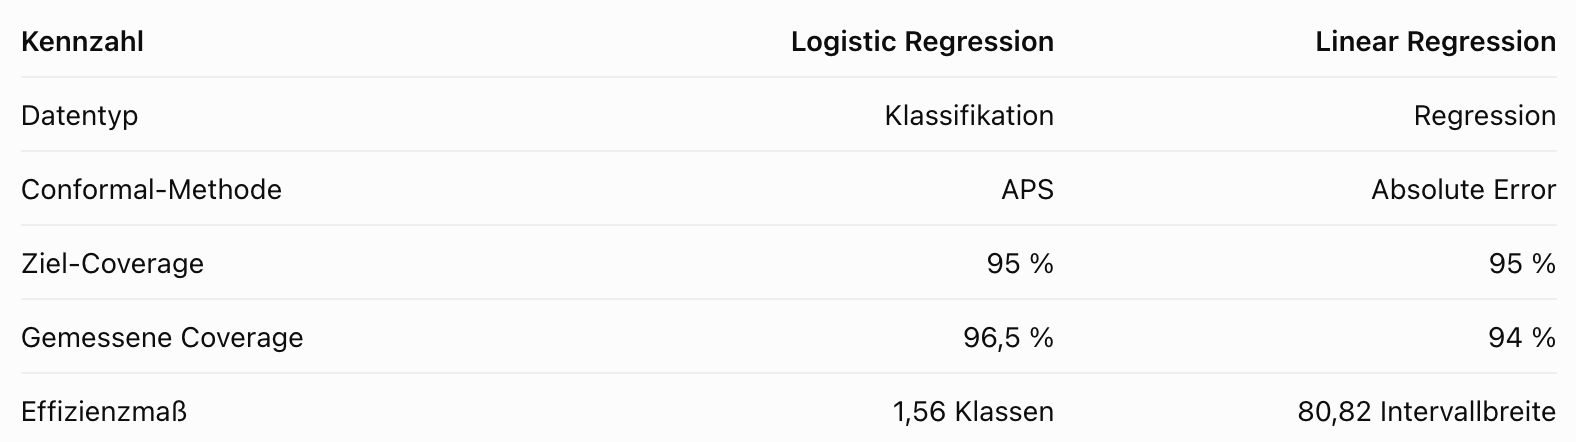

Probly Paper - IS MARGIN ALL YOU NEED?:
Die Kernaussage:

Eine sehr einfache Active-Learning-Methode namens Margin Sampling kann bei tabellarischen Klassifikationsdaten genauso gut oder sogar besser funktionieren als viele deutlich komplexere Methoden.

Das ist überraschend, weil es viele neuere Active-Learning-Methoden gibt, die versuchen, noch intelligentere Datenpunkte auszuwählen.

Die Forschenden vergleichen diese Methoden systematisch und kommen zu dem Ergebnis: Komplexer bedeutet nicht automatisch besser.

Warum ist das wichtig?

Beim Active Learning wollen wir möglichst wenige Datenpunkte labeln müssen, aber trotzdem ein gutes Modell trainieren. Wenn eine einfache Methode genauso gut funktioniert wie eine komplexe, sparen wir Zeit, Rechenleistung und Aufwand.

Was ist Margin Sampling?:
Das ist die wichtigste Methode des Papers.

Margin Sampling gehört zu den sogenannten Uncertainty Sampling-Methoden. Das bedeutet: Wir wählen Datenpunkte aus, bei denen sich das Modell besonders unsicher ist.

Bei einer Klassifikation gibt das Modell für jede Klasse eine Wahrscheinlichkeit aus.

Beispiel: Wir möchten ein Bild entweder als Katze oder Hund klassifizieren.

Die Margin ist die Differenz zwischen den beiden höchsten vorhergesagten Klassenwahrscheinlichkeiten.
Je kleiner die Differenz, desto unsicherer ist das Modell.

Beim Active Learning wählen wir also die Datenpunkte mit dem kleinsten Margin aus, damit diese zuerst gelabelt werden.

Das ist der zentrale Gedanke des Papers.



Welche Methoden werden verglichen?:
Die Forschenden vergleichen Margin Sampling mit zahlreichen anderen Active-Learning-Strategien. Die wichtigsten sind:
Random Sampling, Margin Sampling, Entropy, Least Confident (LC), BALD, Query-by-Committee (QBC), CoreSet, TypiClust



Wie haben die Forschenden experimentiert?:
Die Forschenden verwenden tiefe neuronale Netze:
- Ein fünf-schichtiges neuronales Netzwerk.
- 256 Neuronen pro Schicht.
- ReLU als Aktivierungsfunktion.
- Einen Klassifikationskopf zur Vorhersage der Klassen.

Drei Active-Learning-Szenarien:
1. Small: 30 Startmenge und 10 neue Daten pro Runde
2. Medium: 100 Startmenge und 50 neue Daten pro Runde
3. Large: 300 Startmenge und 200 neue Daten pro Runde
In allen Szenarien werden bis zu 20 Runden durchgeführt.

Das bedeutet beispielsweise im Medium-Szenario:
- Zuerst gibt es 100 gelabelte Datenpunkte.
- Das Modell wird trainiert.
- Margin Sampling wählt 50 neue Datenpunkte aus.
- Diese werden gelabelt und zum Trainingsdatensatz hinzugefügt.
- Das Modell wird neu trainiert.
- Danach beginnt die nächste Runde.
Zusätzlich untersuchen die Forschenden, ob Self-Supervised Pre-Training mit SCARF die Ergebnisse verändert.

SCARF lernt zunächst aus den Merkmalen der Daten, ohne die Labels zu verwenden. Dadurch soll das Modell schon vor dem eigentlichen überwachten Training bessere Repräsentationen der Daten lernen.

Die Ergebnisse werden mit und ohne dieses Pre-Training verglichen. (Paper, Abschnitt 3.1 und 4.1, Seiten 3 und 6–7.)


Was sind die Ergebnisse?
Margin Sampling ist in den untersuchten Szenarien durchgehend eine der stärksten Methoden und wird von keiner der verglichenen Methoden statistisch überzeugend übertroffen. Bei allen Szenarien, also Large, Medium und Small

Das zeigen die Forschenden sowohl ohne als auch mit SCARF-Pre-Training.



Was bedeutet das für unser Probly-Projekt?:
Hier wird es für eure Arbeit besonders interessant.

Wir haben bisher zwei Dinge ausprobiert:
1. Klassifikation: Logistische Regression mit Conformal APS.
2. Regression: Lineare Regression mit Conformal Absolute Error.

Kann man Conformal Prediction als Unsicherheitsmaß für Active Learning verwenden und damit Margin Sampling verbessern?
Dafür könnten wir beispielsweise vergleichen:
- Random Sampling als Baseline.
- Margin Sampling aus dem Paper.
- Eine eigene Auswahlstrategie auf Basis von Conformal Prediction.
